# Load libraries

In [1]:
import h5py
import pandas as pd
import numpy as np
import torch
import math
import matplotlib.pyplot as plt

In [2]:
def get_unique_couplings(data):
    unique_elements = set(data)
    unique_elements_list = sorted(unique_elements)
    final_list = [round(float(elem), 1) for elem in unique_elements_list]
    print(final_list)
    return final_list

def compare_distributions(variable, weights, indices_dictionary, x_range=[0,100], variable_name='',n_bins=40):

        plt.figure(figsize=(10, 6),dpi=100)


        for coupling, indices in indices_dictionary.items():
            if coupling == 0.0:
                weights[indices] = weights[indices]/ 100
            data = variable[indices]
            if variable_name=='W':
                plt.hist(data, bins=n_bins, histtype='step', label=f'Coupling {coupling}', density=False, range=x_range)
            else:
                plt.hist(data, weights=weights[indices], bins=n_bins, histtype='step', label=f'Coupling {coupling}', density=False, range=x_range)

        plt.xlabel(variable_name)
        plt.xlim(x_range[0],x_range[1])
        plt.ylabel('Density')
        plt.title(f'Distribution of {variable_name}')
        plt.legend()
        # plt.yscale('log')
        plt.show()

# Read the inputs.

In [3]:
from numpy.lib import recfunctions as rfn

data_file = h5py.File('../../H5Files_TtbarSBI/Coupling_Inference_negW.h5')
labels_dataset = data_file['LABELS']['CLASS']
signal_indices = np.argwhere(labels_dataset[:] == 1)
background_indices = np.argwhere(labels_dataset[:] == 0)
print('BG events = ',len(background_indices))
print('Signal events = ',len(signal_indices))

couplings_array = data_file['INPUTS']['EVENT_GLOBAL']['coupling'][:]
coupling_values = get_unique_couplings(couplings_array)
indices_per_coupling = {}
for coupling in coupling_values:
    indices = np.argwhere(abs(couplings_array[:] - coupling) < 1e-3)
    indices_per_coupling[coupling] = indices
    print(f'Coupling {coupling}: {len(indices)} events')


# Get 100k of each coupling for training
# Set random seed for reproducibility
np.random.seed(42)
for coupling in coupling_values:
    indices = indices_per_coupling[coupling]
    if len(indices) > 400000:
        selected_indices = np.random.choice(indices.flatten(), 400000, replace=False)
    else:
        selected_indices = indices.flatten()
    indices_per_coupling[coupling] = selected_indices
print(f'Total training events: {sum(len(indices) for indices in indices_per_coupling.values())}')

training_indices = np.concatenate(list(indices_per_coupling.values()))

BG events =  3981348
Signal events =  7793816
[0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0, 1.1, 1.2, 1.4, 1.6]
Coupling 0.0: 3981348 events
Coupling 0.2: 807425 events
Coupling 0.4: 823301 events
Coupling 0.5: 815721 events
Coupling 0.6: 809461 events
Coupling 0.8: 795950 events
Coupling 1.0: 782714 events
Coupling 1.1: 684604 events
Coupling 1.2: 770634 events
Coupling 1.4: 757944 events
Coupling 1.6: 746062 events
Total training events: 4400000


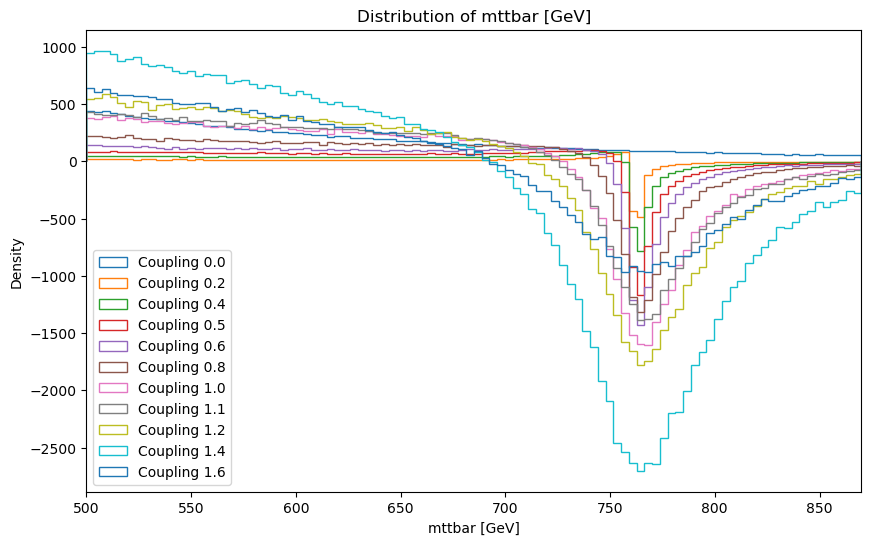

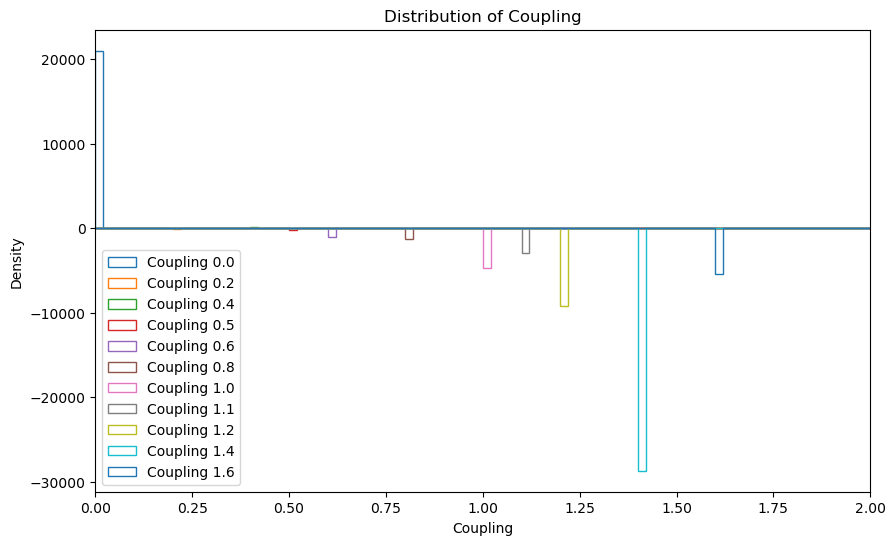

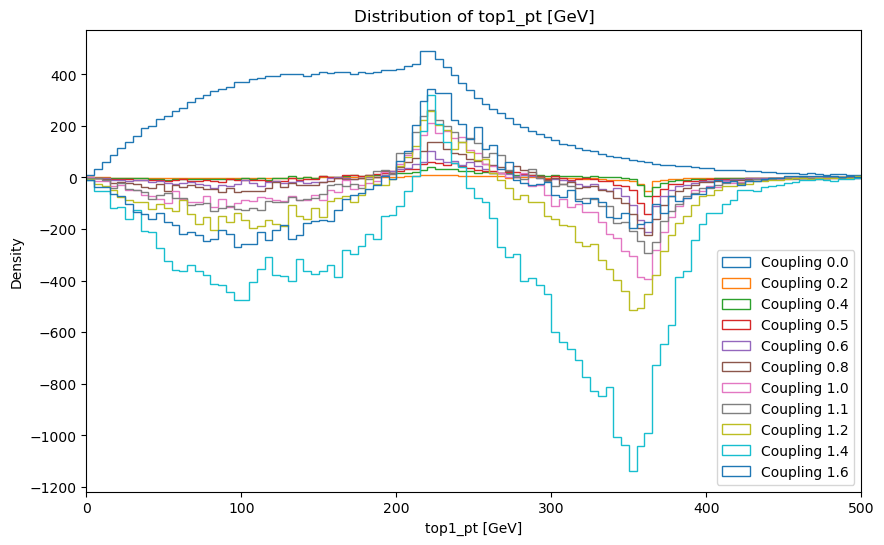

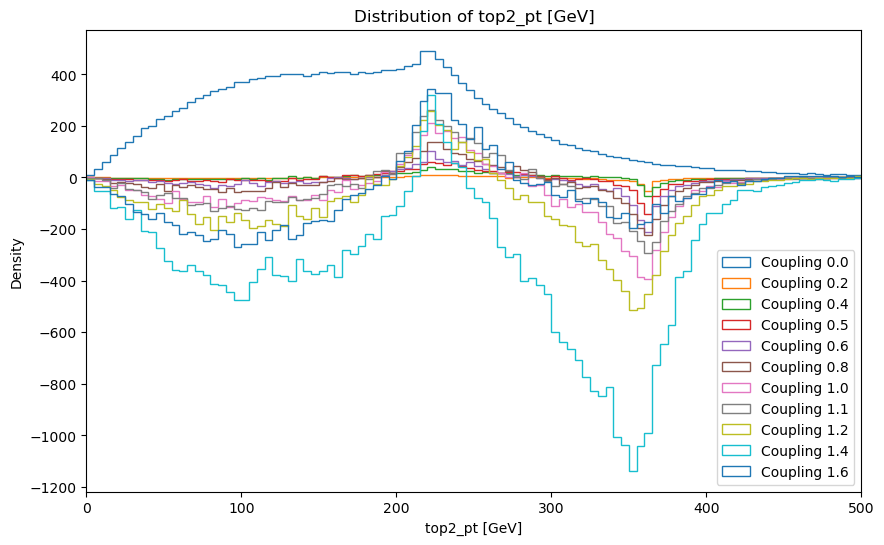

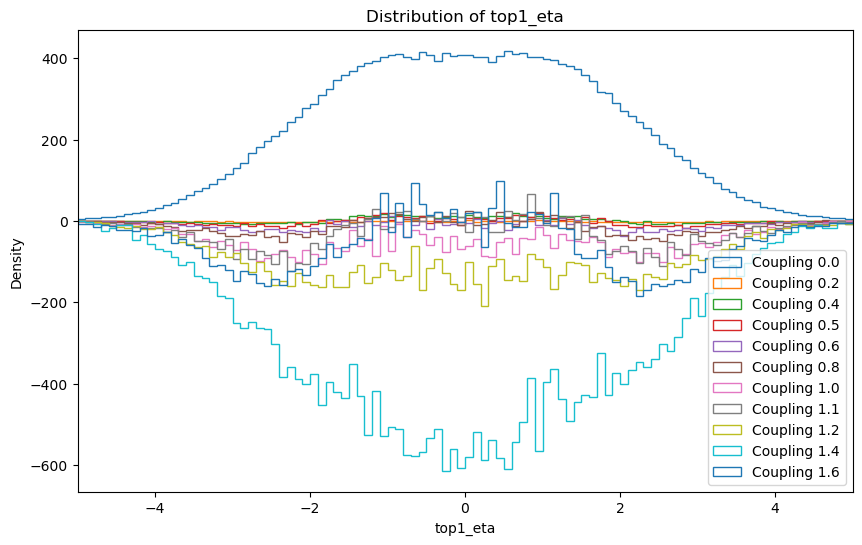

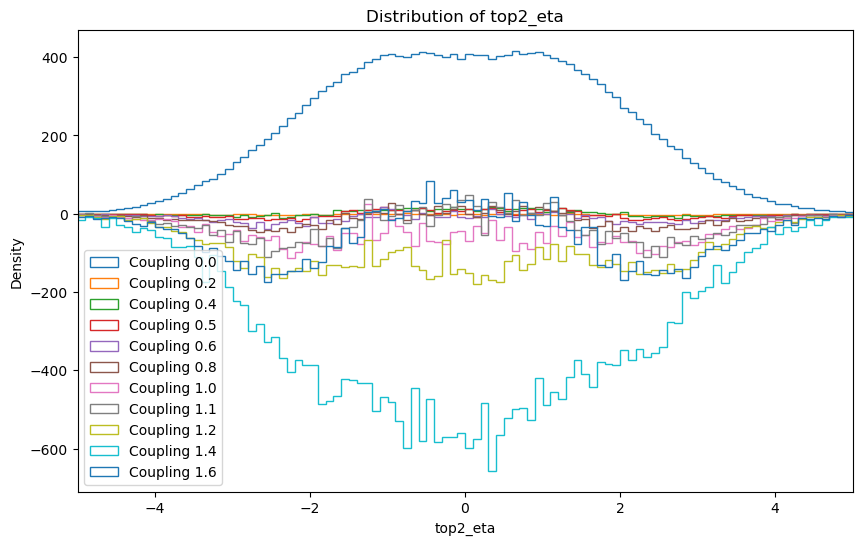

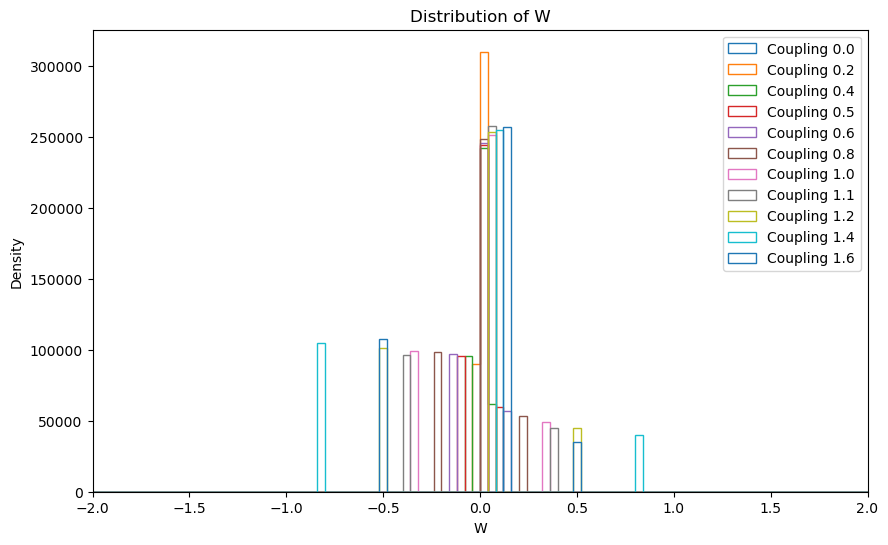

In [4]:
###### 
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['mttbar'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[500,870], variable_name='mttbar [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['coupling'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[0,2], variable_name='Coupling', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top1_pt'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[0,500], variable_name='top1_pt [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top2_pt'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[0,500], variable_name='top2_pt [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top1_eta'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[-5,5], variable_name='top1_eta', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top2_eta'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[-5,5], variable_name='top2_eta', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[-2,2], variable_name='W', n_bins=100)

In [5]:
def structure_data(data_file, coupling_values_for_training, training_indices) -> tuple[np.ndarray, np.ndarray, dict]:
    # Extract the features. 
    X, y = data_file['INPUTS']['EVENT_PARTICLES'][:], labels_dataset[:]
    X = rfn.structured_to_unstructured(X)
    X, y = X[training_indices], y[training_indices]
    X_mttbar = data_file['INPUTS']['EVENT_GLOBAL']['mttbar'][:][training_indices]
    X_couplings = data_file['INPUTS']['EVENT_GLOBAL']['coupling'][:][training_indices]
    X_weights = data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:][training_indices]
    y_category = np.empty_like(y)
    couplings_category_dict = {}
    for i in range(len(coupling_values)):
        couplings_category_dict[float(coupling_values[i])] = i


    # Now fill the category array by loopoing over the X_couplings and assigning the category based on the coupling value
    for i in range(len(X_couplings)):
        coupling_value = X_couplings[i]
        category = couplings_category_dict[round(float(coupling_value), 1)]
        y_category[i] = category
        # Also if the coupling is category 0, give it the first coupling value for training, which is 0.2, later on we will augment the data with the other couplings
        if category == 0:
            X_couplings[i] = coupling_values_for_training[0]

    # Form the data
    X = np.concatenate([X, X_mttbar.reshape(-1, 1), X_couplings.reshape(-1, 1), X_weights.reshape(-1,1)], axis=1)
    y = np.concatenate([y.reshape(-1, 1), y_category.reshape(-1, 1)], axis=1)

    return X, y, couplings_category_dict

def augment_data_for_background(X, y, coupling_values_for_training):
    # Now we want to augment the data, copying every background event giving it every possible coupling.
    background_indices = np.argwhere(y[:, 0] == 0).flatten()
    print("Augmenting data for background events. Number of background events to augment: ", len(background_indices))
    print("Number of augmentations per background event: ", len(coupling_values_for_training) - 1)
    augmented_X = []
    augmented_y = []
    for idx in background_indices:
        for coupling in coupling_values_for_training[1:]:
            new_X = X[idx].copy()
            new_X[-2] = coupling
            augmented_X.append(new_X)
            augmented_y.append(y[idx])

    X_ag = np.concatenate([X, augmented_X], axis=0)
    y_ag = np.concatenate([y, augmented_y], axis=0)

    return X_ag, y_ag

In [6]:
coupling_values_for_training = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6]
X, y, couplings_category_dict = structure_data(data_file, coupling_values_for_training, training_indices)
print('Before augmentation:')
print('X shape = ',X.shape)
print('X example = ',X[1])
print('y shape = ',y.shape)
print('y example = ',y[1])

X_pre_transform, y_pre_transform = augment_data_for_background(X, y, coupling_values_for_training)
print('After augmentation:')
print('X shape = ',X_pre_transform.shape)
print('y shape = ',y_pre_transform.shape)

Before augmentation:
X shape =  (4400000, 9)
X example =  [ 2.3466739e+02  8.1430149e-01 -2.6250648e+00  2.3466739e+02
  4.5949781e-01  5.1652789e-01  5.3600854e+02  2.0000000e-01
  5.2450624e+00]
y shape =  (4400000, 2)
y example =  [0. 0.]
Augmenting data for background events. Number of background events to augment:  400000
Number of augmentations per background event:  7
After augmentation:
X shape =  (7200000, 9)
y shape =  (7200000, 2)


In [7]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
device = 'cpu'
print(f"Using {device} device")

Using cpu device


In [8]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

class LogScaler(BaseEstimator, TransformerMixin):
    def __init__(self, offset=1e-3, add_mask = False):
        self.offset = offset
        self.add_mask = add_mask

    def fit(self, X, y=None):
        return self  # no fitting needed

    def transform(self, X):
        log = np.log(X + self.offset)
        # Create a mask for nan values
        mask = np.isnan(log)
        if self.add_mask:
            return np.hstack([mask, log])
        return log

class PhiTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        sin_phi = np.sin(X)
        cos_phi = np.cos(X)
        return np.hstack([sin_phi, cos_phi])


from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler


scaler = ColumnTransformer(
    [('pt',LogScaler(), [0,3]),
    ('eta',StandardScaler(), [1,4]),
    # ('phi', PhiTransformer(), [2,5]),
    ('mttbar', StandardScaler(), [6]),
    ('coupling', MinMaxScaler(), [7]),
    ('weights', 'passthrough', [8])
    ],
    remainder='drop'
)

X = scaler.fit_transform(X_pre_transform)
y = y_pre_transform
print("X shape after scaling = ", X.shape)
print("X example after scaling = ", X[1])

X shape after scaling =  (7200000, 7)
X example after scaling =  [ 5.4581733   5.4581733   0.51392335  0.28945988 -1.1743859   0.
  5.2450624 ]


# Separate the datasets for new observations

In [9]:
# Print the dictionary to help user steer the code
for key, values in couplings_category_dict.items():
    print(key, ' --> ', values)

0.0  -->  0
0.2  -->  1
0.4  -->  2
0.5  -->  3
0.6  -->  4
0.8  -->  5
1.0  -->  6
1.1  -->  7
1.2  -->  8
1.4  -->  9
1.6  -->  10


In [10]:
coupling_0p5_indices = np.argwhere(y[:,1]==3)
coupling_1p1_indices = np.argwhere(y[:,1]==7)

X_inference_1 = X[coupling_0p5_indices]
X_inference_2 = X[coupling_1p1_indices]
y_inference_1 = y[coupling_0p5_indices]
y_inference_2 = y[coupling_1p1_indices]

# Remove these indices from the dataset
X = np.delete(X, np.concatenate((coupling_0p5_indices, coupling_1p1_indices)), axis=0)
y = np.delete(y, np.concatenate((coupling_0p5_indices, coupling_1p1_indices)), axis=0)

In [11]:
# Split in train, val, test
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
train_indices, test_indices = next(sss.split(X, y))

X_train, y_train = X[train_indices], y[train_indices]
X_temp, y_temp = X[test_indices], y[test_indices]
X_val, X_test, y_val, y_test     = train_test_split(X_temp, y_temp, test_size=0.5, shuffle=True)

print('Train set size = ', X_train.shape)
print('Validation set size = ', X_val.shape)
print('Test set size = ', X_test.shape)

Train set size =  (5120000, 7)
Validation set size =  (640000, 7)
Test set size =  (640000, 7)


In [12]:
# As tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_val, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val, dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test, dtype=torch.float32)

In [13]:
from torch.utils.data import TensorDataset, DataLoader

def create_dataloaders(X_train_tensor, y_train_tensor, X_val_tensor, y_val_tensor, X_test_tensor, y_test_tensor, batch_size=1024, signal="positive", background="positive", weight_column_index=-1, label_column_index=0):
    # First check the signal and background types
    if signal not in ["positive", "negative"]:
        raise ValueError("Signal must be 'positive' or 'negative'")
    if background not in ["positive", "negative"]:
        raise ValueError("Background must be 'positive' or 'negative'")

    # Train dataset masks
    signal_mask = y_train_tensor[:, label_column_index] == 1
    background_mask = y_train_tensor[:, label_column_index] == 0

    if signal == "positive":
        signal_weight_mask = X_train_tensor[:, weight_column_index] >= 0
    else:
        signal_weight_mask = X_train_tensor[:, weight_column_index] < 0
    if background == "positive":
        background_weight_mask = X_train_tensor[:, weight_column_index] >= 0
    else:
        background_weight_mask = X_train_tensor[:, weight_column_index] < 0
    
    train_mask = (signal_mask & signal_weight_mask) | (background_mask & background_weight_mask)
    X_train = X_train_tensor[train_mask]
    y_train = y_train_tensor[train_mask]

    # Validation dataset masks
    signal_mask_val = y_val_tensor[:, label_column_index] == 1
    background_mask_val = y_val_tensor[:, label_column_index] == 0

    if signal == "positive":
        signal_weight_mask_val = X_val_tensor[:, weight_column_index] >= 0
    else:
        signal_weight_mask_val = X_val_tensor[:, weight_column_index] < 0
    if background == "positive":
        background_weight_mask_val = X_val_tensor[:, weight_column_index] >= 0
    else:
        background_weight_mask_val = X_val_tensor[:, weight_column_index] < 0

    val_mask = (signal_mask_val & signal_weight_mask_val) | (background_mask_val & background_weight_mask_val)
    X_val = X_val_tensor[val_mask]
    y_val = y_val_tensor[val_mask]

    # Test dataset masks
    signal_mask_test = y_test_tensor[:, label_column_index] == 1
    background_mask_test = y_test_tensor[:, label_column_index] == 0

    if signal == "positive":
        signal_weight_mask_test = X_test_tensor[:, weight_column_index] >= 0
    else:
        signal_weight_mask_test = X_test_tensor[:, weight_column_index] < 0
    if background == "positive":
        background_weight_mask_test = X_test_tensor[:, weight_column_index] >= 0
    else:
        background_weight_mask_test = X_test_tensor[:, weight_column_index] < 0

    test_mask = (signal_mask_test & signal_weight_mask_test) | (background_mask_test & background_weight_mask_test)
    X_test = X_test_tensor[test_mask]
    y_test = y_test_tensor[test_mask]


    # Form the datasets
    train_dataset = TensorDataset(X_train,
                                  y_train)
    val_dataset   = TensorDataset(X_val,
                                  y_val)
    test_dataset  = TensorDataset(X_test,
                                    y_test)

    # Create DataLoader objects for training, validation, and testing in batches
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=6, persistent_workers=True, drop_last=True)
    val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=6, persistent_workers=True, drop_last=True)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=6)

    print("Training batches = ", len(train_loader))
    print("Validation batches = ", len(val_loader))
    print("Test batches = ", len(test_loader))
    

    return train_loader, val_loader, test_loader

In [14]:
import torch.nn as nn
# Define the Classifier
class RatioEstimator(nn.Module):
    def __init__(self, x_dim, theta_dim = 0, hidden_dim = 64):
        super(RatioEstimator, self).__init__()
        self.theta_dim = theta_dim
        if self.theta_dim == 0:
            print("NN: Using non-parametric model.")
            print("X dimension =", x_dim)
        else:
            print("NN: Using parametric model with theta dimension =", theta_dim)
            print("X dimension =", x_dim)
        self.net = nn.Sequential(
            nn.Linear(x_dim + theta_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=0.05),
            nn.Linear(hidden_dim, hidden_dim//2),
            nn.ReLU(),
            nn.Dropout(p=0.05),
            nn.Linear(hidden_dim//2, 1),
        )

    def forward(self, X, theta):
        model_input = torch.cat([X, theta], dim=1)
        logits = self.net(model_input)
        return logits
    
def norm_weights_per_batch(weights, categories):
    # Extract what categories are present in the batch
    unique_categories = torch.unique(categories)
    number_of_categories = len(unique_categories)
    # For each category, compute the sum of weights and normalize the weights in that category
    for category in unique_categories:
        category_mask = (categories == category)
        category_size = (category_mask).sum()
        if category_size > 0 and category!=0:
            # For the time being only signal/interference events can have negative weights.
            # Normalise them separately
            positive_w_mask = (weights >= 0) & category_mask
            positive_w_sum = weights[positive_w_mask].sum()
            weights[positive_w_mask] = weights[positive_w_mask] / (positive_w_sum * (number_of_categories-1))
            
            weights_negative_mask = (weights < 0) & category_mask
            weights[weights_negative_mask] = torch.abs(weights[weights_negative_mask])
            category_weights_sum = weights[category_mask].sum()
            weights[weights_negative_mask] = weights[weights_negative_mask] / (category_weights_sum * (number_of_categories-1))
        elif category_size > 0 and category==0:
            category_weights_sum = weights[category_mask].sum()
            weights[category_mask] = weights[category_mask] / category_weights_sum
    return weights

In [15]:
# Training loop on mini-batches with loss stored for plotting
import time
def train(model, criterion, optimizer, scheduler, train_loader, val_loader, n_epochs=200, device='cpu'):
    start_time = time.time()
    train_losses = []
    val_losses = []
    
    model.to(device)
    
    for epoch in range(n_epochs):
        epoch_start_time = time.time()
        model.train()
        # run over batches of data
        running_loss = 0.0
        for inputs, targets in train_loader:
            optimizer.zero_grad()
            inputs_device = inputs.to(device)
            targets_device = targets[:,0].to(device)
            categories_device = targets[:,1].to(device)
            X = inputs_device[:,:-2]
            theta = inputs_device[:,-2].unsqueeze(1)
            outputs = model(X, theta)
            # outputs = torch.sigmoid(outputs)
            # Weight according to (1/W_1)*wi_1 + (1/W_0)*wi_0
            weights = inputs_device[:,-1]
            norm_weigths = norm_weights_per_batch(weights, categories_device)
            # Calculate the weighted loss
            loss = criterion(outputs.squeeze(), targets_device) * norm_weigths
            loss = torch.sum(loss)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
    
        # compute avergae loss over all batches
        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)
    
        # Validation step
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs_device = inputs.to(device)
                targets_device = targets[:,0].to(device)
                categories_device = targets[:,1].to(device)
                X = inputs_device[:,:-2]
                theta = inputs_device[:,-2].unsqueeze(1)
                outputs = model(X, theta)
                # outputs = torch.sigmoid(outputs)
                # Weight according to (1/W_1)*wi_1 + (1/W_0)*wi_0
                weights = inputs_device[:,-1]
                norm_weigths = norm_weights_per_batch(weights, categories_device)
                # Calculate the weighted loss
                loss = criterion(outputs.squeeze(), targets_device) * norm_weigths
                loss = torch.sum(loss)
                val_loss += loss.item()
    
        val_loss /= len(val_loader)
        val_losses.append(val_loss)
        scheduler.step(val_loss)

        current_time = time.time()
        print(f"Total Time: {round(current_time - start_time,1)}s, Epoch Time: {round(current_time - epoch_start_time,2)}s")
        print(f"Learning rate: {scheduler.get_last_lr()[0]}")
        print(f"Epoch {epoch+1}/{n_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    # Plot loss function for training and validation sets
    plt.plot(train_losses, label='Train Loss', color='red')
    plt.plot(val_losses, label='Validation Loss', color='green')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Train Loss', 'Validation Loss'])
    plt.show()

In [16]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
model_pp = RatioEstimator(x_dim = 5, theta_dim = 1, hidden_dim = 64)
criterion = nn.BCEWithLogitsLoss(reduction='none')
optimizer_pp = optim.AdamW(model_pp.parameters(), lr=0.0002, weight_decay=1e-3)
scheduler_pp = ReduceLROnPlateau(optimizer_pp, "min", patience=10, factor=0.8)

train_loader_pp, val_loader_pp, test_loader_pp = create_dataloaders(X_train_tensor, y_train_tensor,
                                                                X_val_tensor, y_val_tensor,
                                                                X_test_tensor, y_test_tensor,
                                                                batch_size=2048,
                                                                signal="positive",
                                                                background="positive")

NN: Using parametric model with theta dimension = 1
X dimension = 5
Training batches =  2189
Validation batches =  273
Test batches =  274


Total Time: 17.8s, Epoch Time: 17.78s
Learning rate: 0.0002
Epoch 1/150, Train Loss: 1.1865, Val Loss: 1.1437
Total Time: 26.3s, Epoch Time: 8.55s
Learning rate: 0.0002
Epoch 2/150, Train Loss: 1.1400, Val Loss: 1.1341
Total Time: 34.6s, Epoch Time: 8.32s
Learning rate: 0.0002
Epoch 3/150, Train Loss: 1.1342, Val Loss: 1.1311
Total Time: 45.7s, Epoch Time: 11.1s
Learning rate: 0.0002
Epoch 4/150, Train Loss: 1.1320, Val Loss: 1.1296
Total Time: 54.5s, Epoch Time: 8.77s
Learning rate: 0.0002
Epoch 5/150, Train Loss: 1.1304, Val Loss: 1.1278
Total Time: 62.9s, Epoch Time: 8.41s
Learning rate: 0.0002
Epoch 6/150, Train Loss: 1.1293, Val Loss: 1.1281
Total Time: 71.3s, Epoch Time: 8.4s
Learning rate: 0.0002
Epoch 7/150, Train Loss: 1.1285, Val Loss: 1.1269
Total Time: 80.1s, Epoch Time: 8.78s
Learning rate: 0.0002
Epoch 8/150, Train Loss: 1.1277, Val Loss: 1.1260
Total Time: 88.6s, Epoch Time: 8.48s
Learning rate: 0.0002
Epoch 9/150, Train Loss: 1.1273, Val Loss: 1.1260
Total Time: 96.9s, 

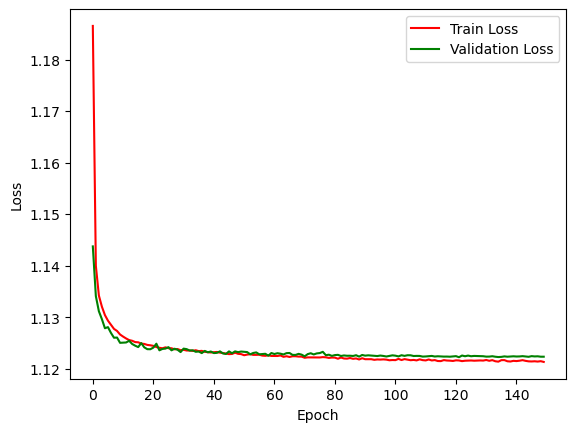

In [65]:
# Train pp model
train(model_pp, criterion, optimizer_pp, scheduler_pp, train_loader_pp, val_loader_pp, n_epochs=150, device=device)

In [66]:
def save_model(model, model_name, skip_confirmation = False):
    import os
    save_model = False
    if skip_confirmation:
        save_model = True
    else:
        save_model = input("Do you want to save the model? [y/n]") == "y"

    if not save_model:
        print("Model not saved")
        return
        
    if model_name in os.listdir():
        overwrite = input("Model already in the directory. Overwrite? [y/n]") =="y"
        if not overwrite:
            print("Model not saved")
            return
    
    print("Saving model...")
    torch.save(model.state_dict(), model_name)


save_model(model_pp, 'Coupling_Inference_SI_vs_BG_PP.pth', skip_confirmation = False)

Saving model...


NN: Using parametric model with theta dimension = 1
X dimension = 5


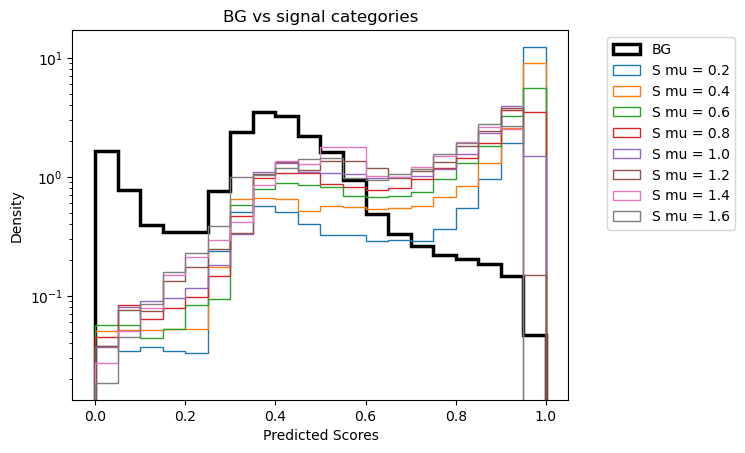

In [17]:
load_model = True
if load_model:
    eval_model = RatioEstimator(x_dim = 5, theta_dim = 1, hidden_dim = 64)
    eval_model.load_state_dict(torch.load('Coupling_Inference_SI_vs_BG_PP.pth', weights_only=True,map_location=torch.device('cpu')))
    model_pp = eval_model
else:
    eval_model = model_pp


eval_model.to('cpu')
eval_model.eval()

X_test_cpu = test_loader_pp.dataset.tensors[0].to('cpu')
y_test_cpu = test_loader_pp.dataset.tensors[1].to('cpu')

y_pred = torch.sigmoid(eval_model(X_test_cpu[:,:-2],X_test_cpu[:,-2].unsqueeze(1)).detach())

# Filter the predicted events for true Signal and true Background
sb_label = y_test_cpu[:,0]
category_label = y_test_cpu[:,1]
true_bkg = y_pred[sb_label==0].numpy()
training_categories = np.unique(category_label[sb_label==1])
training_categories = [int(cat) for cat in training_categories]

plt.hist(true_bkg, bins=20, histtype='step', label='Background', density=True, color='black', linewidth=2.5, range=[0,1])
plt.xlabel("Predicted Scores")
plt.ylabel("Density")
plt.title("BG vs signal categories")
#plt.xlim((0.7,0.9))
plt.yscale('log')
signal_legends = []
for icat in training_categories:
    # Plot the predicted scores for both true Signal and true Background events
    true_signal = y_pred[category_label==icat].numpy()
    plt.hist(true_signal, bins=20, histtype='step', label='Signal', density=True, range=[0,1])
    signal_legends.append(f"S mu = %s" % str(round(coupling_values[icat],2)))

plt.legend(["BG"]+signal_legends,bbox_to_anchor=(1.35, 1), loc='upper right')
plt.show()

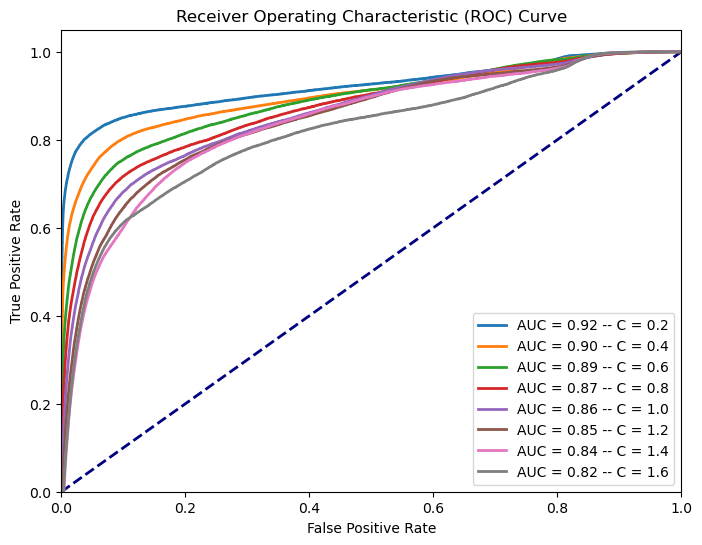

In [18]:
# Compute ROC curve
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Random classifier line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')

for icat in training_categories:
    y_pred_cat = y_pred[(category_label==icat) | (category_label==0)].numpy()
    y_test_cat = y_test_cpu[(category_label==icat) | (category_label==0)]
    fpr, tpr, thresholds = roc_curve(y_test_cat[:,0], y_pred_cat)
    # Compute AUC (Area Under Curve)
    roc_auc = auc(fpr, tpr)
    # Plot ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.2f} -- C = {round(coupling_values[icat],2)}')
    
plt.legend(loc='lower right')
plt.show()

In [19]:
model_pn = RatioEstimator(x_dim = 5, theta_dim = 1, hidden_dim = 64)
criterion = nn.BCEWithLogitsLoss(reduction='none')
optimizer_pn = optim.AdamW(model_pn.parameters(), lr=0.0002, weight_decay=1e-3)
scheduler_pn = ReduceLROnPlateau(optimizer_pn, "min", patience=10, factor=0.8)

train_loader_pn, val_loader_pn, test_loader_pn = create_dataloaders(X_train_tensor, y_train_tensor,
                                                                X_val_tensor, y_val_tensor,
                                                                X_test_tensor, y_test_tensor,
                                                                batch_size=2048,
                                                                signal="negative",
                                                                background="positive")

NN: Using parametric model with theta dimension = 1
X dimension = 5
Training batches =  1560
Validation batches =  194
Test batches =  196


Total Time: 15.3s, Epoch Time: 15.3s
Learning rate: 0.0002
Epoch 1/150, Train Loss: 0.7373, Val Loss: 0.6277
Total Time: 22.3s, Epoch Time: 7.01s
Learning rate: 0.0002
Epoch 2/150, Train Loss: 0.6251, Val Loss: 0.6064
Total Time: 28.9s, Epoch Time: 6.56s
Learning rate: 0.0002
Epoch 3/150, Train Loss: 0.6121, Val Loss: 0.5996
Total Time: 35.4s, Epoch Time: 6.51s
Learning rate: 0.0002
Epoch 4/150, Train Loss: 0.6074, Val Loss: 0.5966
Total Time: 42.3s, Epoch Time: 6.89s
Learning rate: 0.0002
Epoch 5/150, Train Loss: 0.6049, Val Loss: 0.5955
Total Time: 48.9s, Epoch Time: 6.65s
Learning rate: 0.0002
Epoch 6/150, Train Loss: 0.6028, Val Loss: 0.5943
Total Time: 56.4s, Epoch Time: 7.53s
Learning rate: 0.0002
Epoch 7/150, Train Loss: 0.6017, Val Loss: 0.5932
Total Time: 63.7s, Epoch Time: 7.25s
Learning rate: 0.0002
Epoch 8/150, Train Loss: 0.6008, Val Loss: 0.5931
Total Time: 70.3s, Epoch Time: 6.61s
Learning rate: 0.0002
Epoch 9/150, Train Loss: 0.6001, Val Loss: 0.5927
Total Time: 76.8s, 

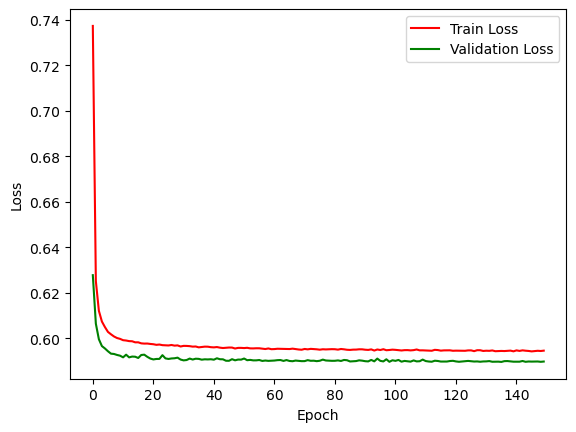

In [76]:
train(model_pn, criterion, optimizer_pn, scheduler_pn, train_loader_pn, val_loader_pn, n_epochs=150, device=device)

In [77]:
save_model(model_pn, 'Coupling_Inference_SI_vs_BG_PN.pth', skip_confirmation = True)

Saving model...


NN: Using parametric model with theta dimension = 1
X dimension = 5
Doing category = 1
Doing category = 2
Doing category = 4
Doing category = 5
Doing category = 6
Doing category = 8
Doing category = 9
Doing category = 10


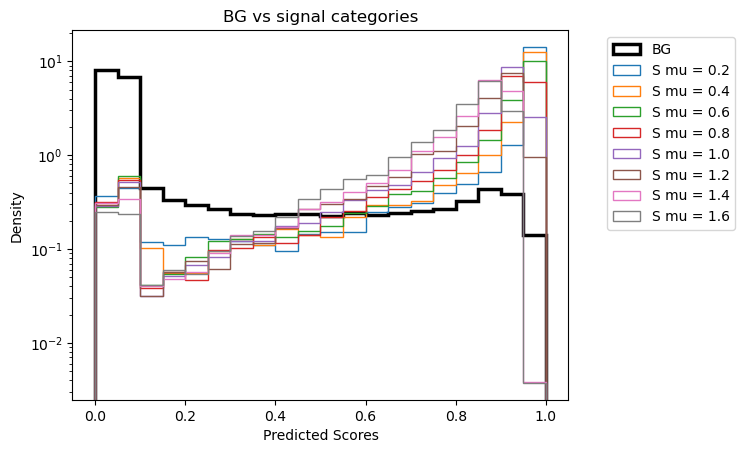

In [20]:
load_model = True
if load_model:
    eval_model = RatioEstimator(x_dim = 5, theta_dim = 1, hidden_dim = 64)
    eval_model.load_state_dict(torch.load('Coupling_Inference_SI_vs_BG_PN.pth', weights_only=True,map_location=torch.device('cpu')))
    model_pn = eval_model
else:
    eval_model = model_pn


eval_model.to('cpu')
eval_model.eval()

X_test_cpu = test_loader_pn.dataset.tensors[0].to('cpu')
y_test_cpu = test_loader_pn.dataset.tensors[1].to('cpu')

y_pred = torch.sigmoid(eval_model(X_test_cpu[:,:-2],X_test_cpu[:,-2].unsqueeze(1)).detach())

# Filter the predicted events for true Signal and true Background
sb_label = y_test_cpu[:,0]
category_label = y_test_cpu[:,1]
true_bkg = y_pred[sb_label==0].numpy()
training_categories = np.unique(category_label[sb_label==1])
training_categories = [int(cat) for cat in training_categories]

plt.hist(true_bkg, bins=20, histtype='step', label='Background', density=True, color='black', linewidth=2.5, range=[0,1])
plt.xlabel("Predicted Scores")
plt.ylabel("Density")
plt.title("BG vs signal categories")
#plt.xlim((0.7,0.9))
plt.yscale('log')
signal_legends = []
for icat in training_categories:
    # Plot the predicted scores for both true Signal and true Background events
    print(f"Doing category = {icat}")
    true_signal = y_pred[category_label==icat].numpy()
    plt.hist(true_signal, bins=20, histtype='step', label='Signal', density=True, range=[0,1])
    signal_legends.append(f"S mu = %s" % str(round(coupling_values[icat],2)))

plt.legend(["BG"]+signal_legends,bbox_to_anchor=(1.35, 1), loc='upper right')
plt.show()

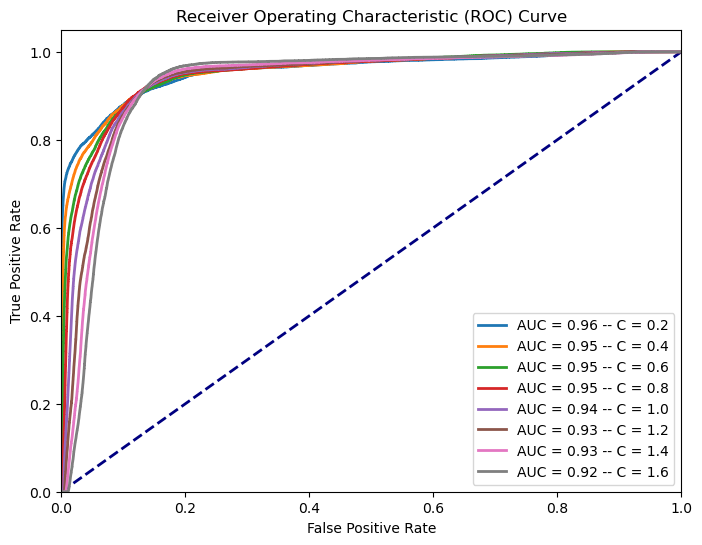

In [21]:
# Compute ROC curve
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Random classifier line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')

for icat in training_categories:
    y_pred_cat = y_pred[(category_label==icat) | (category_label==0)].numpy()
    y_test_cat = y_test_cpu[(category_label==icat) | (category_label==0)]
    fpr, tpr, thresholds = roc_curve(y_test_cat[:,0], y_pred_cat)
    # Compute AUC (Area Under Curve)
    roc_auc = auc(fpr, tpr)
    # Plot ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.2f} -- C = {round(coupling_values[icat],2)}')
    
plt.legend(loc='lower right')
plt.show()

In [22]:
# Calculate the mixture coefficcients

# C(y) = Sum(wi for wi >0) / Sum(wi) with wi belonging to the "y" category

# First C0 -> This is one because the BG weights are all positive
bg_mask = y_train[:,0]==0
signal_mask = y_train[:,0]==1
C_zero = (X_train[bg_mask & (X_train[:,-1]>=0)][:,-1]).sum()/ X_train[bg_mask][:,-1].sum() 
print("C0 =", C_zero)

# Now C1
C_one = (X_train[signal_mask & (X_train[:,-1]>=0)][:,-1]).sum()/ (X_train[signal_mask][:,-1]).sum()
print("C1 =", C_one)

C0 = 1.0
C1 = -4.322442


400000
(400000, 9)
[14826.73535156 14028.88574219 13609.67285156 13473.1328125
 13060.56640625 12644.04589844 12481.52148438 13038.23632812
 11931.04492188 11771.70996094 11995.62695312 11359.30957031
 10944.51660156 10678.61230469  9892.49804688  8930.15917969
  9214.0234375   9181.06835938  9222.81738281  9130.78515625
  9032.34082031  8538.34082031  8519.37695312  8365.97167969
  7830.64111328  8452.05175781  7999.70605469  7795.03222656
  7864.88720703  7540.55224609  7198.59912109  6882.45214844
  6529.21435547  6355.03613281  6364.81787109  6273.25634766
  6035.65771484  6556.46484375  6058.30273438  5947.59716797
  6343.71044922  6011.38867188  5832.70166016  5519.50195312
  5466.53613281  5104.99267578  5076.36328125  4944.48535156
  4693.55664062  4887.48486328]


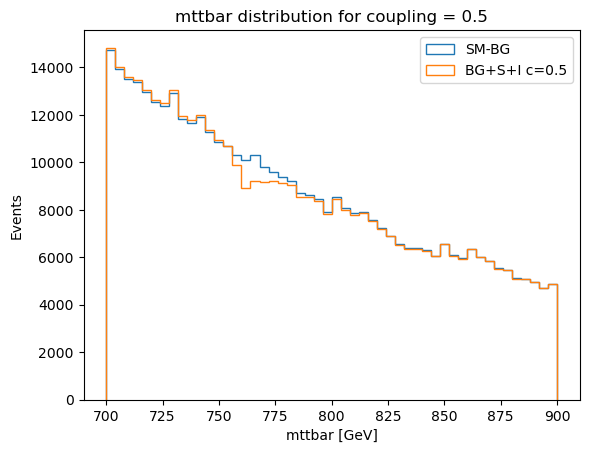

In [23]:
def Logits(x_obs, theta, eval_model):
    logits = eval_model(x_obs, theta)
    logits = logits.reshape(-1)
    return logits

def likelihood_ratio(theta, X_obs, eval_model):
    thetas = theta.unsqueeze(0).expand(len(X_obs), -1)
    logits = Logits(X_obs, thetas, eval_model)
    scores = torch.sigmoid(logits)
    llh_ratio = scores / (1-scores)
    return llh_ratio

def RoSMM(theta_tensor, X_obs, model_pp, model_pn, C_zero, C_one):
    llr_pp = likelihood_ratio(theta_tensor, X_obs, model_pp)
    llr_pn = likelihood_ratio(theta_tensor, X_obs, model_pn)
    rosmm = llr_pp * C_one/C_zero + llr_pn * (1-C_one)/C_zero
    return rosmm

bg_mask = np.bitwise_and(y_pre_transform[:,0] == 0, X_pre_transform[:,-2] == 0.2)
print(bg_mask.sum())
sig_mask = coupling_0p5_indices
bg_data =  X_pre_transform[bg_mask].reshape(-1,X_pre_transform.shape[1])
print(bg_data.shape)
bg_weights = bg_data[:,-1]
bg_mttbar = bg_data[:,-3]
plt.hist(bg_mttbar, weights=bg_weights, bins=50, histtype='step', label=f'SM-BG', density=False, range=[700,900])

sig_mask = y_pre_transform[:,1] == 3
# append the bg_mask to the sig_mask with a bitwise or
sig_mask = np.bitwise_or(sig_mask, bg_mask)
sig_data =  X_pre_transform[sig_mask].reshape(-1,X_pre_transform.shape[1])
sig_weights = sig_data[:,-1]
sig_mttbar = sig_data[:,-3]
counts_and_bins = plt.hist(sig_mttbar, weights=sig_weights, bins=50, histtype='step', label=f'BG+S+I c=0.5', density=False, range=[700,900])
print(counts_and_bins[0])
plt.xlabel("mttbar [GeV]")
plt.ylabel("Events")
plt.title("mttbar distribution for coupling = 0.5")
plt.legend()

plt.show()


In [78]:
import boost_histogram as bh

def inference_shape_from_reference(theta, X_ref, model_pp, model_pn, C_zero, C_one, hypothesis_shape, plot = False):
    # print("Number of background events used for inference = ", X_ref.shape[0])
    theta_transformed = scaler["coupling"].transform([[theta]])[0,0]
    theta_tensor = torch.tensor([theta_transformed], dtype=torch.float32)

    # Perform the inference using the RoSMM model
    re_w = RoSMM(theta_tensor, torch.tensor(X_ref[:,:-2], dtype=torch.float32), model_pp, model_pn, C_zero, C_one)
    inference_w = -1.0 * re_w.detach().numpy()
    inference_w = inference_w / (np.abs(inference_w).sum()/np.abs(hypothesis_shape).sum())

    m_ttbar_ref_transformed = X_ref[:,-3]
    # Reverse the transformation of mttbar
    m_ttbar_ref = scaler.named_transformers_['mttbar'].inverse_transform(m_ttbar_ref_transformed.reshape(-1,1)).reshape(-1)

    m_ttbar_histo = bh.Histogram( bh.axis.Regular(50, 500, 1200), storage=bh.storage.Weight())
    m_ttbar_histo.fill(m_ttbar_ref, weight=inference_w)

    # Plot the hypothesis shape for comparison
    if plot:
        yields_and_bins = plt.hist(m_ttbar_ref, weights=inference_w, bins=50, histtype='step', label=f'BG reweighted from RoSMM = {round(theta, 2)}', density=False, range=[500,1200])
        plt.stairs(hypothesis_shape, yields_and_bins[1], label=f'Hypothesis shape', color='red')
        plt.title("Inference shape vs hypothesis shape")
        plt.xlabel("mttbar [GeV]")
        plt.ylabel("Events")
        plt.legend()
        plt.show()

    return m_ttbar_histo.view().value, m_ttbar_histo.view().variance

def shape_of_hypothesis(X_hypo):
    weights = X_hypo[:,-1]
    weights = weights / abs(weights.sum())
    hypo_mttbar = X_hypo[:,-3]

    m_ttbar_histo = bh.Histogram( bh.axis.Regular(50, 500, 1200), storage=bh.storage.Weight())
    m_ttbar_histo.fill(hypo_mttbar, weight=weights)

    hypo_shape_and_bins = plt.hist(hypo_mttbar, weights=weights, bins=50, histtype='step', label=f'S+I c=0.5', density=False, range=[500,1200])
    plt.title("Shape of the hypothesis")
    plt.xlabel("mttbar [GeV]")
    plt.ylabel("Events")
    plt.legend()
    plt.show()
    return m_ttbar_histo.view().value, m_ttbar_histo.view().variance

def chi_squared(observed, expected, observed_variance, expected_variance):
    # Add a small value to expected to avoid division by zero
    chi2 = np.sum(((observed - expected) ** 2) / (expected_variance))
    return chi2

def parameter_inference(theta_scan, X_ref, model_pp, model_pn, C_zero, C_one, hypothesis_shape, hypothesis_variance):
    # Loop through all the theta values and get the chi2 with respect to the hypothesis shape

    chi2_values = []
    for itheta in theta_scan:
        # print("Scanning theta = ", round(itheta, 2))
        inference_shape, inference_variance = inference_shape_from_reference(itheta, X_ref, model_pp, model_pn, C_zero, C_one, hypothesis_shape)
        chi2 = chi_squared(hypothesis_shape, inference_shape, hypothesis_variance, inference_variance)
        chi2_values.append(chi2)

    plt.plot(theta_scan, chi2_values)
    plt.xlabel("Theta")
    plt.ylabel("Chi2")
    plt.xlim((min(theta_scan),max(theta_scan)))
    plt.show()

    return chi2_values

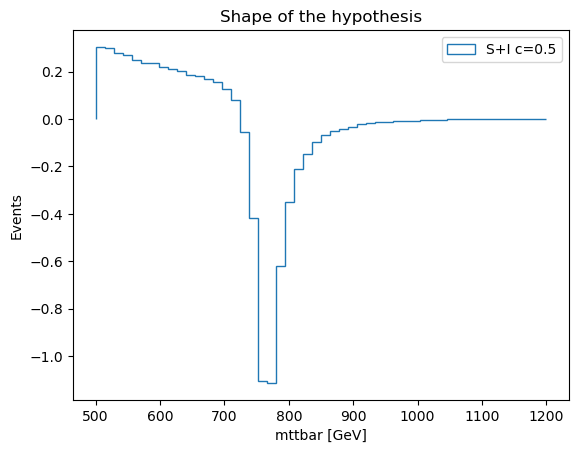

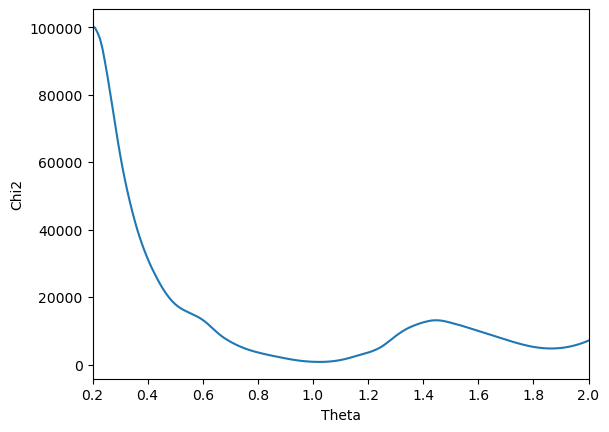

Minimum chi2 value =  781.4911025718101  at theta =  1.0231155778894472


In [89]:
theta_scan = np.linspace(0.2,2.0,200)
bg_test_mask = np.bitwise_and(y_test[:,0]==0, X_test[:,-2] >=0.98)
X_test_bg = X_test[bg_test_mask]

sig_mask = y_pre_transform[:,1] == 6
sig_data =  X_pre_transform[sig_mask]
hypothesis_shape, hypothesis_variance = shape_of_hypothesis(sig_data)

chi2_values = parameter_inference(theta_scan, X_test_bg, model_pp, model_pn, C_zero, C_one, hypothesis_shape, hypothesis_variance)
print("Minimum chi2 value = ", min(chi2_values), " at theta = ", theta_scan[np.argmin(chi2_values)])

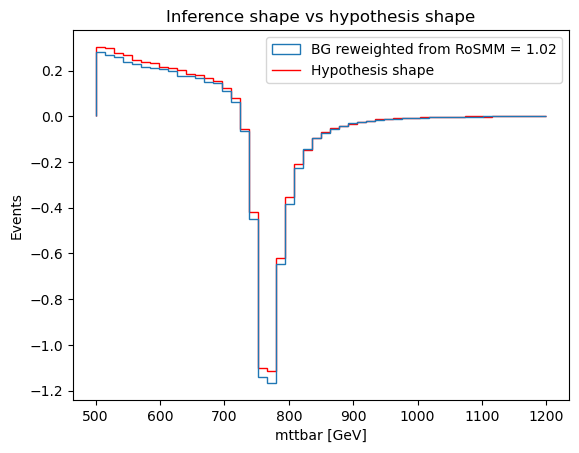

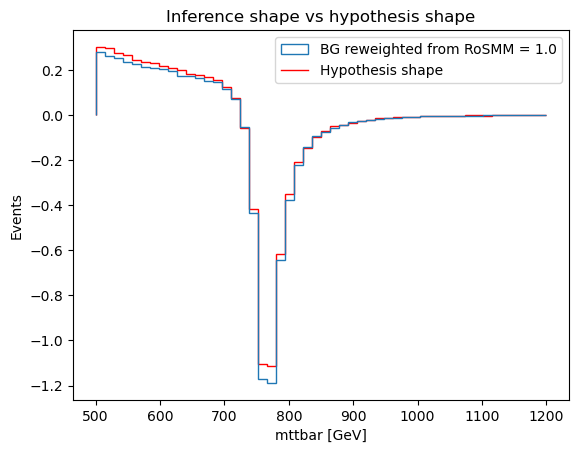

In [90]:
best_inference_shape = inference_shape_from_reference(theta_scan[np.argmin(chi2_values)], X_test_bg, model_pp, model_pn, C_zero, C_one, hypothesis_shape, plot=True)
best_inference_shape = inference_shape_from_reference(1.0, X_test_bg, model_pp, model_pn, C_zero, C_one, hypothesis_shape, plot=True)

In [77]:

0.0  -->  0
0.2  -->  1
0.4  -->  2
0.5  -->  3
0.6  -->  4
0.8  -->  5
1.0  -->  6
1.1  -->  7
1.2  -->  8
1.4  -->  9
1.6  -->  10


SyntaxError: invalid syntax (4239637667.py, line 1)